In [247]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [248]:
Y0 = [950, 50, 0] #Initial distribution
N = 1000 #Tot number of individuals
n = 300 #number of timesteps

#Func. for calculating beta_n (prob. S -> I)
def beta_n(In):
    return 0.5*In/N

alfa = 0.005 #Prob. R -> S
gamma = 0.1 #Prob. I -> R


def new_individuals(Yn):
    
    I_new = np.random.binomial(n = Yn[0], p = beta_n(Yn[1]))
    S_new = np.random.binomial(n = Yn[2] , p = alfa)
    R_new = np.random.binomial(n = Yn[1] , p = gamma)

    return I_new, S_new, R_new


#Initial distributions
S = int(Y0[0])
I = int(Y0[1])
R = int(Y0[2])
Yn = Y0

Yn_history = [Y0]
S_history = [Y0[0]]
I_history = [Y0[1]]
R_history = [Y0[2]]

for i in range(n):
    I_new, S_new, R_new = new_individuals(Yn)
    
    #Calculating the next individual distribution
    I_next = I - R_new + I_new
    S_next = S - I_new + S_new
    R_next = R - S_new + R_new

    Yn = [S_next, I_next, R_next]
    Yn_history.append(Yn)
    S_history.append(Yn[0])
    I_history.append(Yn[1])
    R_history.append(Yn[2])

    I = I_next
    S = S_next
    R = R_next

print(Yn_history)
print(S_history)


[[950, 50, 0], [919, 77, 4], [894, 89, 17], [860, 112, 28], [814, 149, 37], [762, 182, 56], [683, 247, 70], [608, 299, 93], [528, 343, 129], [439, 398, 163], [364, 428, 208], [282, 470, 248], [216, 494, 290], [161, 492, 347], [120, 490, 390], [97, 468, 435], [75, 443, 482], [58, 416, 526], [44, 393, 563], [32, 358, 610], [22, 344, 634], [19, 315, 666], [14, 285, 701], [17, 253, 730], [23, 229, 748], [19, 208, 773], [20, 194, 786], [21, 181, 798], [22, 170, 808], [26, 156, 818], [29, 139, 832], [31, 129, 840], [36, 117, 847], [40, 103, 857], [44, 96, 860], [46, 94, 860], [49, 87, 864], [49, 77, 874], [52, 74, 874], [57, 67, 876], [58, 60, 882], [61, 61, 878], [68, 56, 876], [73, 53, 874], [77, 52, 871], [81, 49, 870], [78, 49, 873], [85, 44, 871], [88, 42, 870], [86, 42, 872], [92, 37, 871], [94, 36, 870], [99, 30, 871], [103, 28, 869], [106, 23, 871], [108, 22, 870], [110, 19, 871], [116, 20, 864], [120, 18, 862], [124, 18, 858], [121, 19, 860], [125, 15, 860], [130, 13, 857], [133, 10

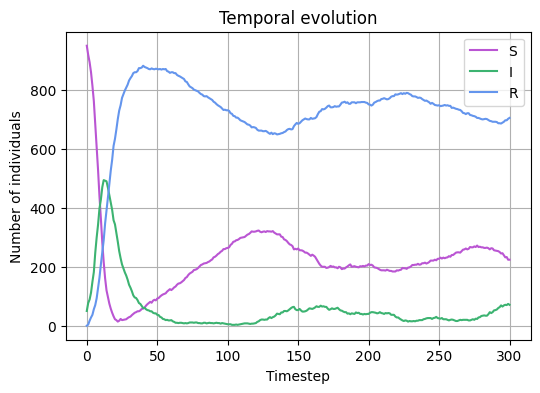

In [249]:
#Plotting the temporal evolution
n_vals = np.linspace(0, n, 301)
plt.figure(figsize=(6,4))
plt.plot(n_vals, S_history, color = 'mediumorchid', label = 'S')
plt.plot(n_vals, I_history, color = 'mediumseagreen', label = 'I')
plt.plot(n_vals, R_history, color = 'cornflowerblue', label = 'R')

plt.xlabel('Timestep')
plt.ylabel('Number of individuals')
plt.title('Temporal evolution')
plt.grid(True)
plt.legend(loc = 'best')
plt.show()



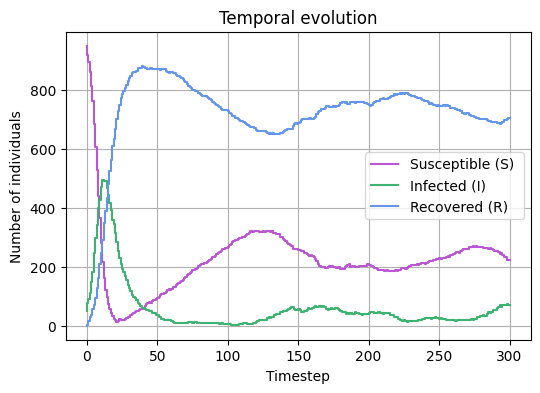

In [250]:
#Plotting the temporal evolution - with plt.step
n_vals = np.linspace(0, n, 301)
plt.figure(figsize=(6,4))
plt.step(n_vals, S_history, color = 'mediumorchid', label = 'Susceptible (S) ')
plt.step(n_vals, I_history, color = 'mediumseagreen', label = 'Infected (I)')
plt.step(n_vals, R_history, color = 'cornflowerblue', label = 'Recovered (R)')

plt.xlabel('Timestep')
plt.ylabel('Number of individuals')
plt.title('Temporal evolution')
plt.grid(True)
plt.legend(loc = 'best')
plt.show()



### Task f)

In [251]:
I_max = []
exp_time_first_I_max = []

#Func. for calculating beta_n (prob. S -> I)
def beta_n(In):
    return 0.5*In/N

alfa = 0.005 #Prob. R -> S
gamma = 0.1 #Prob. I -> R

#rng = np.random.default_rng(seed = 42)

def new_individuals(Yn):
        
    I_new = np.random.binomial(n = Yn[0], p = beta_n(Yn[1]))
    S_new = np.random.binomial(n = Yn[2] , p = alfa)
    R_new = np.random.binomial(n = Yn[1] , p = gamma)

    return I_new, S_new, R_new

for j in range(1000):
    Y0 = [950, 50, 0] #Initial distribution
    N = 1000 #Tot number of individuals
    n = 300 #number of timesteps

    #Initial distributions
    S = int(Y0[0])
    I = int(Y0[1])
    R = int(Y0[2])
    Yn = Y0

    Yn_history = [Y0]
    S_history = [Y0[0]]
    I_history = [Y0[1]]
    R_history = [Y0[2]]

    for i in range(n):
        I_new, S_new, R_new = new_individuals(Yn)
        
        #Calculating the next individual distribution
        I_next = I - R_new + I_new
        S_next = S - I_new + S_new
        R_next = R - S_new + R_new

        Yn = [S_next, I_next, R_next]
        Yn_history.append(Yn)
        S_history.append(Yn[0])
        I_history.append(Yn[1])
        R_history.append(Yn[2])

        I = I_next
        S = S_next
        R = R_next
    exp_time_first_I_max.append(np.argmax(I_history))
    I_max.append(np.max(I_history))


Expected_I_max = np.mean(I_max)
Expected_time_first_I_max = np.mean(exp_time_first_I_max)
print(Expected_I_max)
print(Expected_time_first_I_max)

523.651
11.899


In [261]:
n_simulations = 1000
t_value = 1.960


def CI(exp_values):   
    mean = np.mean(exp_values)

    s = np.sqrt(1/(n_simulations-1)*sum((mean-exp_values)**2))

    SE = np.sqrt(s**2/n_simulations)

    lower = mean - t_value*SE
    upper = mean + t_value*SE

    return np.array([lower, upper])

#Computing the confidence interval for every state
CI_exp_I_max = CI(I_max)
CI_exp_time_first_I_max = CI(exp_time_first_I_max)



#Plotting a table for the CI's
ci_df = pd.DataFrame({
    "E[max(I)]" : CI_exp_I_max, 
    "E[min[argmax(I)]]" : CI_exp_time_first_I_max},
    index = ["Lower", "Upper"]
     
    )

display(
    ci_df.style
    .set_caption("95% Confidence Intervals")
    .set_table_styles([
        {
            "selector":"caption",
            "props" : [("font-size", "20px")]
        }
    ])
    .format("{:2f}")
    .set_properties(**{
        "font-size": "16px",
        "min-width": "120px",
        "padding" : "10px"
    })
    .background_gradient(cmap = "tab20b", axis = None)
)


,E[max(I)],E[min[argmax(I)]]
Lower,522.415860,11.847984
Upper,524.886140,11.950016
